In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

SEED = 42
DATA_PATH = r"C:\Users\USER\archive (18)\american_bankruptcy.csv"

In [2]:
%pip install lightgbm scikit-learn pandas matplotlib

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 9.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [9]:
NAMES = {
    "X1": "current_assets", "X2": "cogs", "X3": "dep_amort", "X4": "ebitda",
    "X5": "inventory", "X6": "net_income", "X7": "receivables", "X8": "market_value",
    "X9": "net_sales", "X10": "total_assets", "X11": "long_term_debt", "X12": "ebit",
    "X13": "gross_profit", "X14": "current_liab", "X15": "retained_earnings",
    "X16": "total_revenue", "X17": "total_liab", "X18": "operating_expenses",
}
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig").rename(columns=NAMES)
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)

print(df.shape, "| companies:", df.company_name.nunique())
print("Missing:", df.isna().sum().sum())
print("Duplicate firm-year:", df.duplicated(["company_name", "year"]).sum())
df.head()

(78682, 21) | companies: 8971
Missing: 0
Duplicate firm-year: 0


,company_name,status_label,year,current_assets,cogs,dep_amort,ebitda,inventory,net_income,receivables,...,net_sales,total_assets,long_term_debt,ebit,gross_profit,current_liab,retained_earnings,total_revenue,total_liab,operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,...,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,1024.333,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,...,874.255,701.854,179.987,45.790,160.444,125.392,204.065,874.255,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,...,638.721,710.199,217.699,4.711,112.244,150.464,139.603,638.721,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,...,606.337,686.621,164.658,3.573,109.590,203.575,124.106,606.337,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,...,651.958,709.292,248.666,20.811,128.656,131.261,131.884,651.958,407.608,604.467


Companies whose label ever changes: 0
Matches the paper: True
Positives: 609 (0.77%)


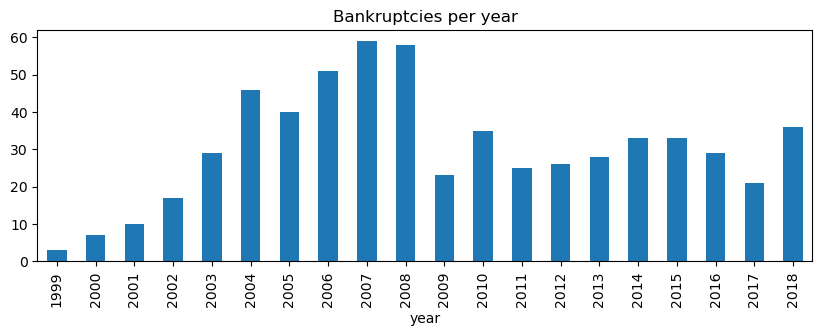

In [10]:
changes = df.groupby("company_name").status_label.nunique()
print("Companies whose label ever changes:", (changes > 1).sum())

# Positive = last observed year of a failed company
is_last = df.year == df.groupby("company_name").year.transform("max")
df["target"] = ((df.status_label == "failed") & is_last).astype(int)

# Verify against Table 1 of the paper (bankruptcies per year, 1999-2018 in this file)
paper = [3,7,10,17,29,46,40,51,59,58,23,35,25,26,28,33,33,29,21,36]
yearly = df.groupby("year").target.sum()
print("Matches the paper:", (yearly.values == paper).all())
print("Positives:", df.target.sum(), f"({df.target.mean():.2%})")

yearly.plot.bar(figsize=(10, 3), title="Bankruptcies per year")
plt.show()

In [11]:
def safe_div(a, b):
    return a / b.where(b.abs() > 1e-9)

d = df
F = pd.DataFrame(index=d.index)
# Altman Z-score components
F["wc_to_assets"] = safe_div(d.current_assets - d.current_liab, d.total_assets)
F["retained_to_assets"] = safe_div(d.retained_earnings, d.total_assets)
F["ebit_to_assets"] = safe_div(d.ebit, d.total_assets)
F["mktval_to_liab"] = safe_div(d.market_value, d.total_liab)
F["sales_to_assets"] = safe_div(d.net_sales, d.total_assets)
# Profitability, liquidity, leverage, size
F["roa"] = safe_div(d.net_income, d.total_assets)
F["ebitda_margin"] = safe_div(d.ebitda, d.net_sales)
F["gross_margin"] = safe_div(d.gross_profit, d.net_sales)
F["current_ratio"] = safe_div(d.current_assets, d.current_liab)
F["quick_ratio"] = safe_div(d.current_assets - d.inventory, d.current_liab)
F["liab_to_assets"] = safe_div(d.total_liab, d.total_assets)
F["ltdebt_to_assets"] = safe_div(d.long_term_debt, d.total_assets)
F["log_assets"] = np.log1p(d.total_assets.clip(lower=0))
F["log_mktval"] = np.log1p(d.market_value.clip(lower=0))

# Year-over-year changes, only when the previous row is exactly one year earlier
prev = d.groupby("company_name").shift(1)
consecutive = (d.year - prev.year) == 1
for col in ["total_assets", "net_sales", "market_value", "total_liab"]:
    F[f"{col}_growth"] = safe_div(d[col] - prev[col], prev[col].abs()).where(consecutive)
for col in ["roa", "liab_to_assets", "wc_to_assets"]:
    F[f"{col}_change"] = (F[col] - F.groupby(d.company_name)[col].shift(1)).where(consecutive)

F = F.replace([np.inf, -np.inf], np.nan)
FEATURES = list(F.columns)
data = pd.concat([d[["company_name", "year", "target"]], F], axis=1)
print(len(FEATURES), "features")

21 features


train 55927 rows | 403 bankrupt
valid 10473 rows | 87 bankrupt
test 12282 rows | 119 bankrupt


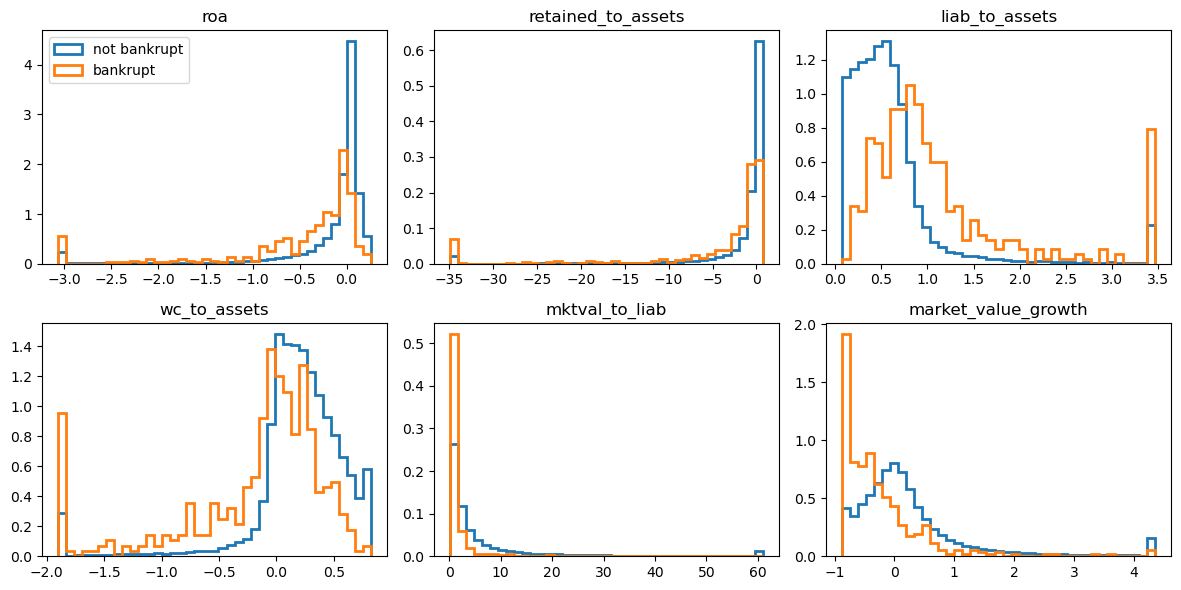

In [12]:
train = data[data.year <= 2011]
valid = data[data.year.between(2012, 2014)]
test = data[data.year >= 2015]
for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(name, len(part), "rows |", part.target.sum(), "bankrupt")

# EDA uses training data only
cols = ["roa", "retained_to_assets", "liab_to_assets",
        "wc_to_assets", "mktval_to_liab", "market_value_growth"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, cols):
    lo, hi = train[col].quantile([0.02, 0.98])
    bins = np.linspace(lo, hi, 40)
    for flag, label in [(0, "not bankrupt"), (1, "bankrupt")]:
        values = train.loc[train.target == flag, col].dropna().clip(lo, hi)
        ax.hist(values, bins=bins, density=True, histtype="step", lw=2, label=label)
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [24]:
# Same model, original label, two ways of splitting
raw = df[list(NAMES.values())]
y_status = (df.status_label == "failed").astype(int)
splitters = {
    "random rows": StratifiedKFold(5, shuffle=True, random_state=SEED),
    "grouped by company": StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
}
results = {}
for name, cv in splitters.items():
    scores = []
        # Pass groups only to the splitter that uses them
    groups = df.company_name if name == "grouped by company" else None
    for tr, te in cv.split(raw, y_status, groups=groups):
        m = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
        m.fit(raw.iloc[tr], y_status.iloc[tr])
        p = m.predict_proba(raw.iloc[te])[:, 1]
        scores.append([roc_auc_score(y_status.iloc[te], p),
                       average_precision_score(y_status.iloc[te], p)])
    results[name] = np.mean(scores, axis=0)
pd.DataFrame(results, index=["ROC-AUC", "PR-AUC"]).T.round(3)

,ROC-AUC,PR-AUC
random rows,0.851,0.441
grouped by company,0.690,0.144


In [26]:
def evaluate(frame, score):
    # Recall@10%: inspect the riskiest 10% of companies in each year
    rank = pd.Series(score, index=frame.index).groupby(frame.year).rank(
        ascending=False, pct=True, method="first")
    return {
        "PR-AUC": average_precision_score(frame.target, score),
        "ROC-AUC": roc_auc_score(frame.target, score),
        "Recall@10%": frame.target[rank <= 0.10].sum() / frame.target.sum(),
    }

def altman_risk(frame):
    # Negated Altman Z-score, so higher means riskier
    z = (1.2 * frame.wc_to_assets + 1.4 * frame.retained_to_assets
         + 3.3 * frame.ebit_to_assets + 0.6 * frame.mktval_to_liab
         + 1.0 * frame.sales_to_assets)
    return -z.fillna(z.median()).to_numpy()

In [22]:
def make_logreg(C):
    return make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        QuantileTransformer(output_distribution="normal", random_state=SEED),
        LogisticRegression(C=C, max_iter=5000))

def make_rf(leaf):
    return make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestClassifier(n_estimators=400, min_samples_leaf=leaf,
                               random_state=SEED, n_jobs=-1))

def make_lgbm(num_leaves):
    return lgb.LGBMClassifier(
        num_leaves=num_leaves, n_estimators=500, learning_rate=0.01,
        min_child_samples=100, subsample=0.8, subsample_freq=1,
        colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1)

grids = {
    "Logistic Regression": (make_logreg, [0.01, 0.1, 1.0]),
    "Random Forest": (make_rf, [5, 20, 50, 100]),
    "LightGBM": (make_lgbm, [4, 8, 16]),
}
best, rows = {}, {"Altman Z": evaluate(valid, altman_risk(valid))}
for name, (factory, params) in grids.items():
    for param in params:
        model = factory(param).fit(train[FEATURES], train.target)
        res = evaluate(valid, model.predict_proba(valid[FEATURES])[:, 1])
        if name not in best or res["PR-AUC"] > rows[name]["PR-AUC"]:
            best[name], rows[name] = param, res

val_table = pd.DataFrame(rows).T.sort_values("PR-AUC", ascending=False)
print("Best params:", best)
val_table.round(3)

Best params: {'Logistic Regression': 0.1, 'Random Forest': 20, 'LightGBM': 8}


,PR-AUC,ROC-AUC,Recall@10%
Random Forest,0.219,0.898,0.667
LightGBM,0.218,0.915,0.747
Logistic Regression,0.074,0.905,0.736
Altman Z,0.022,0.808,0.195


In [29]:
chosen = val_table.drop("Altman Z")["PR-AUC"].idxmax()  
dev = data[data.year <= 2014]

scores = {"Altman Z": altman_risk(test)}
for name, (factory, _) in grids.items():
    model = factory(best[name]).fit(dev[FEATURES], dev.target)
    scores[name] = model.predict_proba(test[FEATURES])[:, 1]

print("Chosen model:", chosen)
print("Random-guess PR-AUC:", round(test.target.mean(), 4))
pd.DataFrame({n: evaluate(test, s) for n, s in scores.items()}).T.round(3)

Chosen model: Random Forest
Random-guess PR-AUC: 0.0097


,PR-AUC,ROC-AUC,Recall@10%
Altman Z,0.026,0.794,0.227
Logistic Regression,0.156,0.899,0.706
Random Forest,0.330,0.932,0.748
LightGBM,0.286,0.929,0.748


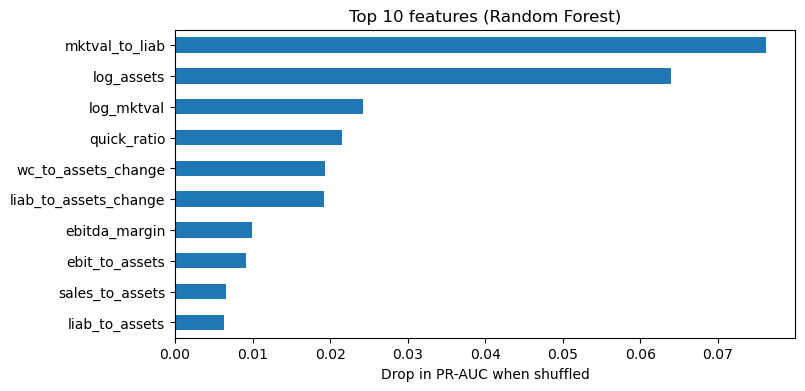

In [30]:
model = grids[chosen][0](best[chosen]).fit(train[FEATURES], train.target)
imp = permutation_importance(model, valid[FEATURES], valid.target,
                             scoring="average_precision", n_repeats=10, random_state=SEED)
top = pd.Series(imp.importances_mean, index=FEATURES).nlargest(10)
top[::-1].plot.barh(figsize=(8, 4), title=f"Top 10 features ({chosen})")
plt.xlabel("Drop in PR-AUC when shuffled")
plt.show()

In [31]:
from pathlib import Path

OUT = Path(r"C:\Users\USER\bankcruptcy-prediction DS Project")

cols = ["company_name", "year", "target", "roa", "liab_to_assets",
        "wc_to_assets", "retained_to_assets", "mktval_to_liab"]
out = test[cols].copy()
out["risk_score"] = scores[chosen]
# Rank within each year (1 = riskiest)
out["risk_rank"] = out.groupby("year").risk_score.rank(ascending=False, method="first").astype(int)
out.to_csv(OUT / "scores.csv", index=False)

metrics = pd.DataFrame({n: evaluate(test, s) for n, s in scores.items()}).T
metrics.to_csv(OUT / "metrics.csv", index_label="model")
print("Saved to:", OUT)

Saved to: C:\Users\USER\bankcruptcy-prediction DS Project
